# Backtesting de VaR: ¿qué tanto se puede confiar en Kupiec, Christoffersen y el semáforo de Basilea?

**Perfil:** Riesgo financiero y riesgo de modelos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un backtest dice "el modelo pasa" o "el modelo falla". Pero ¿con qué frecuencia una prueba rechaza un modelo **correcto** (tamaño), y con qué frecuencia detecta uno **incorrecto** (potencia), con las ventanas de 250 días que se usan en la práctica? ¿Y qué método de VaR pasa en un mundo con agrupamiento de volatilidad?

## Recorrido

1. Las pruebas: Kupiec (cobertura), Christoffersen (independencia) y cobertura condicional; semáforo de Basilea.
2. **Calibración de las pruebas:** tamaño bajo la nula, con la versión asintótica y la exacta.
3. **Potencia:** contra tasas de excepción distintas y contra excepciones **agrupadas**, por tamaño de ventana.
4. **El mundo con volatilidad agrupada (GARCH t):** cinco métodos de VaR y su comportamiento ante las pruebas.
5. Semáforo en el tiempo, robustez, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats
from numpy.lib.stride_tricks import sliding_window_view

## 2. Las pruebas

Sea $x_t=\mathbf 1\{\text{pérdida}_t>\mathrm{VaR}_t\}$ la **excepción** del día $t$. Si el VaR al nivel $q$ es correcto, las excepciones son **Bernoulli($p=1-q$) independientes**.

- **Kupiec (POF, cobertura incondicional):** contrasta que la tasa de excepciones sea $p$. $\mathrm{LR}_{\text{pof}}=-2\ln\frac{(1-p)^{n-k}p^{k}}{(1-k/n)^{n-k}(k/n)^{k}}\sim\chi^2_1$, con $k$ excepciones en $n$ días.
- **Christoffersen (independencia):** contrasta que las excepciones no se **agrupen**, con una cadena de Markov de dos estados. $\mathrm{LR}_{\text{ind}}\sim\chi^2_1$.
- **Cobertura condicional:** $\mathrm{LR}_{\text{cc}}=\mathrm{LR}_{\text{pof}}+\mathrm{LR}_{\text{ind}}\sim\chi^2_2$.
- **Kupiec exacto:** prueba binomial exacta (sin aproximación asintótica).

In [2]:
def xlogx(a, b):
    # a * log(b) con la convencion 0*log(0)=0
    a = np.asarray(a, float); b = np.asarray(b, float)
    return np.where(a == 0, 0.0, a * np.log(np.where(b == 0, 1.0, b)))

def lr_pof(x, p):
    n, k = len(x), int(np.sum(x))
    ll0 = xlogx(n - k, 1 - p) + xlogx(k, p)
    ll1 = xlogx(n - k, 1 - k / n) + xlogx(k, k / n)
    return float(-2 * (ll0 - ll1))

def lr_ind(x):
    x = np.asarray(x, int)
    n00 = int(((x[:-1] == 0) & (x[1:] == 0)).sum()); n01 = int(((x[:-1] == 0) & (x[1:] == 1)).sum())
    n10 = int(((x[:-1] == 1) & (x[1:] == 0)).sum()); n11 = int(((x[:-1] == 1) & (x[1:] == 1)).sum())
    pi01 = n01 / max(n00 + n01, 1); pi11 = n11 / max(n10 + n11, 1); pi = (n01 + n11) / max(n00 + n01 + n10 + n11, 1)
    ll0 = xlogx(n00 + n10, 1 - pi) + xlogx(n01 + n11, pi)
    ll1 = xlogx(n00, 1 - pi01) + xlogx(n01, pi01) + xlogx(n10, 1 - pi11) + xlogx(n11, pi11)
    return float(-2 * (ll0 - ll1))

def pvalores(x, p):
    a, b = lr_pof(x, p), lr_ind(x)
    return {"pof": 1 - stats.chi2.cdf(a, 1), "ind": 1 - stats.chi2.cdf(b, 1), "cc": 1 - stats.chi2.cdf(a + b, 2),
            "exacto": stats.binomtest(int(np.sum(x)), len(x), p).pvalue}

# verificacion con un calculo a mano antes de usar las pruebas
x_ej = np.zeros(250, int); x_ej[[10, 60, 61, 130, 200]] = 1                    # 5 excepciones en 250 dias, un par consecutivo
print(f"Ejemplo: 5 excepciones en 250 dias (p=1%): LR_pof = {lr_pof(x_ej, 0.01):.4f}, LR_ind = {lr_ind(x_ej):.4f}")
manual = -2 * (245 * np.log(0.99) + 5 * np.log(0.01) - (245 * np.log(245 / 250) + 5 * np.log(5 / 250)))
assert abs(lr_pof(x_ej, 0.01) - manual) < 1e-9
assert lr_pof(np.zeros(100, int), 0.01) > 0 and abs(lr_pof(np.r_[np.ones(1), np.zeros(99)].astype(int), 0.01)) < 1e-12   # k/n = p exacto: LR=0
print(pd.Series(pvalores(x_ej, 0.01)).round(4).to_frame("p-valor").T)

Ejemplo: 5 excepciones en 250 dias (p=1%): LR_pof = 1.9568, LR_ind = 3.1540
           pof    ind     cc  exacto
p-valor 0.1619 0.0757 0.0777  0.1078


### El semáforo de Basilea

Con 250 días y $p=1\%$, el comité clasifica por número de excepciones: **verde** 0–4, **amarillo** 5–9, **rojo** $\ge 10$. Se verifica con la distribución binomial las probabilidades que esas zonas tienen bajo un modelo **correcto**: ≈ 89,2 % de caer en verde, ≈ 99,975 % de no pasar de amarillo y solo ≈ 0,025 % de llegar a rojo.

In [3]:
acum = stats.binom.cdf([4, 9], 250, 0.01)
print(f"P(excepciones <= 4 | modelo correcto) = {acum[0]:.4f}  (zona verde)")
print(f"P(excepciones <= 9 | modelo correcto) = {acum[1]:.5f}  (hasta amarillo)")
print(f"Probabilidad de caer en amarillo o rojo con un modelo CORRECTO: {1 - acum[0]:.1%}")

P(excepciones <= 4 | modelo correcto) = 0.8922  (zona verde)
P(excepciones <= 9 | modelo correcto) = 0.99975  (hasta amarillo)
Probabilidad de caer en amarillo o rojo con un modelo CORRECTO: 10.8%


## 3. Calibración: ¿cuántas veces rechaza un modelo correcto?

Se simulan excepciones **exactamente** Bernoulli(1 %) independientes y se cuenta con qué frecuencia cada prueba rechaza al 5 %. Un procedimiento calibrado debería rechazar ≈ 5 %. Hay una razón para sospechar de la versión asintótica: con $p=1\%$ y $n=250$, el número esperado de excepciones es 2,5, demasiado pequeño para que la aproximación $\chi^2$ sea buena.

In [4]:
def tamano(n, p=0.01, R=20_000, seed=0):
    rg = np.random.default_rng(seed)
    X = rg.random((R, n)) < p
    rech = {"pof": 0, "ind": 0, "cc": 0, "exacto": 0}
    for x in X:
        pv = pvalores(x.astype(int), p)
        for k in rech: rech[k] += pv[k] < 0.05
    return {k: v / R for k, v in rech.items()}

tam = pd.DataFrame({n: tamano(n, seed=n, R=6000 if n >= 1000 else 12_000) for n in (250, 500, 1000, 2500)}).T
tam.index.name = "n"
tam.round(4)

,pof,ind,cc,exacto
n,,,,
250,0.1001,0.0130,0.0093,0.0429
500,0.0712,0.0152,0.0171,0.0390
1000,0.0550,0.0175,0.0273,0.0383
2500,0.0453,0.0178,0.0288,0.0453


In [5]:
print("Lectura: tasa de rechazo bajo la nula (nominal 5%):")
for n in tam.index:
    print(f"  n={n:<5d}: Kupiec asintotico {tam.loc[n, 'pof']:.1%} | independencia {tam.loc[n, 'ind']:.1%} | cobertura condicional {tam.loc[n, 'cc']:.1%} | Kupiec exacto {tam.loc[n, 'exacto']:.1%}")
print(f"  Con n=250 el Kupiec asintotico rechaza {tam.loc[250, 'pof']:.1%} (mas del 5% nominal) y el exacto {tam.loc[250, 'exacto']:.1%} (menos). Independencia y cobertura condicional rechazan solo {tam.loc[250, 'ind']:.1%} y {tam.loc[250, 'cc']:.1%}: son conservadoras con pocas excepciones.")
print("  La seccion 3.1 muestra de donde viene el exceso del asintotico.")

Lectura: tasa de rechazo bajo la nula (nominal 5%):
  n=250  : Kupiec asintotico 10.0% | independencia 1.3% | cobertura condicional 0.9% | Kupiec exacto 4.3%
  n=500  : Kupiec asintotico 7.1% | independencia 1.5% | cobertura condicional 1.7% | Kupiec exacto 3.9%
  n=1000 : Kupiec asintotico 5.5% | independencia 1.8% | cobertura condicional 2.7% | Kupiec exacto 3.8%
  n=2500 : Kupiec asintotico 4.5% | independencia 1.8% | cobertura condicional 2.9% | Kupiec exacto 4.5%
  Con n=250 el Kupiec asintotico rechaza 10.0% (mas del 5% nominal) y el exacto 4.3% (menos). Independencia y cobertura condicional rechazan solo 1.3% y 0.9%: son conservadoras con pocas excepciones.
  La seccion 3.1 muestra de donde viene el exceso del asintotico.


### 3.1 ¿De dónde sale el 10 %? Una descomposición exacta

Un dato curioso para investigar: el Kupiec asintótico rechaza ≈ 10 % bajo la nula pero, como se verá en la sección 4, **no tiene más potencia** que el exacto. Hipótesis: su exceso de rechazo viene del lado de **cero excepciones** (un VaR demasiado conservador), que ocurre con probabilidad $0{,}99^{250}\approx 8\%$ bajo la nula, y no del lado de **demasiadas** excepciones, que es el que le importa al riesgo. Se comprueba sin simulación, con la distribución binomial exacta.

In [6]:
N0 = 250; K0 = np.arange(0, 41); PMF = stats.binom.pmf(K0, N0, 0.01)
def rechaza_asint(k):
    x = np.r_[np.ones(k), np.zeros(N0 - k)].astype(int); return lr_pof(x, 0.01) > stats.chi2.ppf(0.95, 1)
def rechaza_exacto(k):
    return stats.binomtest(int(k), N0, 0.01).pvalue < 0.05
ra = np.array([rechaza_asint(int(k)) for k in K0]); rex = np.array([rechaza_exacto(k) for k in K0])
esperado = N0 * 0.01
desc = pd.DataFrame({
    "prueba": ["asintotica", "exacta"],
    "rechaza_con_pocas_excepciones(k<2.5)": [PMF[ra & (K0 < esperado)].sum(), PMF[rex & (K0 < esperado)].sum()],
    "rechaza_con_muchas(k>2.5)": [PMF[ra & (K0 > esperado)].sum(), PMF[rex & (K0 > esperado)].sum()],
}).set_index("prueba"); desc["total"] = desc.sum(axis=1)
print("Probabilidad EXACTA de rechazar bajo la nula con n=250, p=1% (sin simulacion):")
print(desc.round(4).to_string())
print(f"\nLa asintotica rechaza k en {sorted(K0[ra & (K0 < esperado)].tolist())} (poco) y desde k = {K0[ra & (K0 > esperado)].min()} (mucho).")
print(f"La exacta rechaza k en {sorted(K0[rex & (K0 < esperado)].tolist())} (poco) y desde k = {K0[rex & (K0 > esperado)].min()} (mucho).")
print(f"Probabilidad de observar CERO excepciones bajo la nula: {PMF[0]:.4f}")

Probabilidad EXACTA de rechazar bajo la nula con n=250, p=1% (sin simulacion):
            rechaza_con_pocas_excepciones(k<2.5)  rechaza_con_muchas(k>2.5)  total
prueba                                                                            
asintotica                                0.0811                     0.0137 0.0948
exacta                                    0.0000                     0.0412 0.0412

La asintotica rechaza k en [0] (poco) y desde k = 7 (mucho).
La exacta rechaza k en [] (poco) y desde k = 6 (mucho).
Probabilidad de observar CERO excepciones bajo la nula: 0.0811


**Qué muestra.** El exceso del Kupiec asintótico viene **entero del lado de pocas excepciones**: rechaza el caso de cero excepciones (un VaR demasiado holgado), que el exacto no rechaza. Del lado que importa para el riesgo (demasiadas excepciones) la asintótica necesita **una excepción más** para rechazar, por lo que tiene **menos** potencia, no más. Una "mejor calibración" aparente de la exacta no es un defecto de la asintótica en abstracto sino de **dónde** pone sus rechazos.

También conviene notar que las pruebas de **independencia** y de **cobertura condicional** rechazan **menos** del 5 % nominal (1–3 %): con tan pocas excepciones, casi no hay transiciones 1→1 que contar, y esas pruebas son muy conservadoras.

## 4. Potencia: ¿cuántas veces detecta un modelo malo?

Se simulan excepciones bajo dos tipos de modelo defectuoso:

- **Tasa equivocada:** el verdadero porcentaje de excepciones es 1,5 %, 2 % o 3 % (el VaR es demasiado bajo), con excepciones independientes.
- **Agrupamiento:** la tasa incondicional sigue siendo 1 %, pero las excepciones se **agrupan** (cadena de Markov con $\pi_{11}=0{,}25$).

In [7]:
def potencia_tasa(n, p_verd, p=0.01, R=3000, seed=0):
    rg = np.random.default_rng(seed); rech = {"pof": 0, "exacto": 0, "cc": 0}
    for _ in range(R):
        x = (rg.random(n) < p_verd).astype(int); pv = pvalores(x, p)
        for k in rech: rech[k] += pv[k] < 0.05
    return {k: v / R for k, v in rech.items()}

def simular_markov(n, pi01, pi11, rg):
    x = np.zeros(n, int); u = rg.random(n)
    for t in range(1, n): x[t] = u[t] < (pi11 if x[t - 1] else pi01)
    return x

def potencia_agrupada(n, p=0.01, pi11=0.25, R=3000, seed=0):
    # pi01 tal que la tasa estacionaria sea p: pi01 = p * (1 - pi11) / (1 - p)
    pi01 = p * (1 - pi11) / (1 - p); rg = np.random.default_rng(seed); rech = {"pof": 0, "ind": 0, "cc": 0}
    for _ in range(R):
        x = simular_markov(n, pi01, pi11, rg); pv = pvalores(x, p)
        for k in rech: rech[k] += pv[k] < 0.05
    return {k: v / R for k, v in rech.items()}

filas = []
for n in (250, 500, 1000, 2500):
    for p_v in (0.015, 0.02, 0.03):
        r = potencia_tasa(n, p_v, seed=n + int(p_v * 1000)); filas.append({"n": n, "escenario": f"tasa {p_v:.1%}", "Kupiec asintotico": r["pof"], "Kupiec exacto": r["exacto"], "cond. coverage": r["cc"]})
    r = potencia_agrupada(n, seed=n); filas.append({"n": n, "escenario": "agrupado (tasa 1%)", "Kupiec asintotico": r["pof"], "Kupiec exacto": np.nan, "cond. coverage": r["cc"], "independencia": r["ind"]})
pot = pd.DataFrame(filas).set_index(["escenario", "n"])
pot.round(3)

,,Kupiec asintotico,Kupiec exacto,cond. coverage,independencia
escenario,n,,,,
tasa 1.5%,250,0.1150,0.1850,0.0500,NaN
tasa 2.0%,250,0.2420,0.3880,0.1510,NaN
tasa 3.0%,250,0.6290,0.7720,0.5150,NaN
agrupado (tasa 1%),250,0.2060,NaN,0.2100,0.3390
tasa 1.5%,500,0.2220,0.2170,0.0940,NaN
tasa 2.0%,500,0.5550,0.5550,0.3390,NaN
tasa 3.0%,500,0.9350,0.9350,0.8340,NaN
agrupado (tasa 1%),500,0.1600,NaN,0.4230,0.5270
tasa 1.5%,1000,0.3330,0.3320,0.2080,NaN


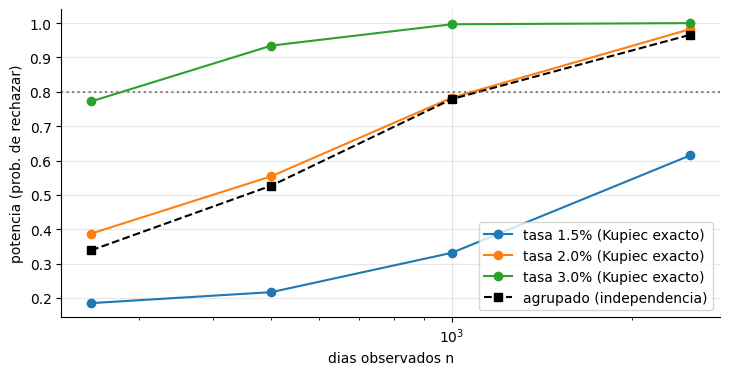

Lectura: potencia con la ventana de Basilea (n=250):
  tasa 1.5%: 19% (exacto) | 11% (asintotico)
  tasa 2.0%: 39% (exacto) | 24% (asintotico)
  tasa 3.0%: 77% (exacto) | 63% (asintotico)
  excepciones agrupadas con tasa correcta: la prueba de independencia las detecta 34% de las veces con n=250 y 97% con n=2500.
  Tamano minimo (de los probados) para 80% de potencia con Kupiec exacto: {'tasa 1.5%': None, 'tasa 2.0%': 2500, 'tasa 3.0%': 500}
  El asintotico tiene MENOS potencia que el exacto con n=250 (p.ej., 24% vs 39% para una tasa de 2%), aunque rechace mas bajo la nula: su exceso de rechazo esta del lado de 'cero excepciones' (seccion 3.1).


In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for esc in ("tasa 1.5%", "tasa 2.0%", "tasa 3.0%"):
    d = pot.loc[esc]; ax.plot(d.index, d["Kupiec exacto"], "o-", label=f"{esc} (Kupiec exacto)")
d = pot.loc["agrupado (tasa 1%)"]; ax.plot(d.index, d["independencia"], "s--", color="k", label="agrupado (independencia)")
ax.set_xscale("log"); ax.set_xlabel("dias observados n"); ax.set_ylabel("potencia (prob. de rechazar)"); ax.axhline(0.8, color="gray", ls=":"); ax.legend(); plt.show()
print("Lectura: potencia con la ventana de Basilea (n=250):")
for esc in ("tasa 1.5%", "tasa 2.0%", "tasa 3.0%"):
    print(f"  {esc}: {pot.loc[(esc, 250), 'Kupiec exacto']:.0%} (exacto) | {pot.loc[(esc, 250), 'Kupiec asintotico']:.0%} (asintotico)")
print(f"  excepciones agrupadas con tasa correcta: la prueba de independencia las detecta {pot.loc[('agrupado (tasa 1%)', 250), 'independencia']:.0%} de las veces con n=250 y {pot.loc[('agrupado (tasa 1%)', 2500), 'independencia']:.0%} con n=2500.")
n80 = {esc: next((n for n in (250, 500, 1000, 2500) if pot.loc[(esc, n), 'Kupiec exacto'] >= 0.8), None) for esc in ("tasa 1.5%", "tasa 2.0%", "tasa 3.0%")}
print(f"  Tamano minimo (de los probados) para 80% de potencia con Kupiec exacto: {n80}")
print(f"  El asintotico tiene MENOS potencia que el exacto con n=250 (p.ej., {pot.loc[('tasa 2.0%', 250), 'Kupiec asintotico']:.0%} vs {pot.loc[('tasa 2.0%', 250), 'Kupiec exacto']:.0%} para una tasa de 2%), aunque rechace mas bajo la nula: su exceso de rechazo esta del lado de 'cero excepciones' (seccion 3.1).")

**Qué muestra.** Con **250 días** el backtest tiene **baja potencia** para detectar un VaR que en realidad deja pasar el doble de excepciones. Un modelo "aprobado" con una ventana corta **no está demostrado correcto**; simplemente no se pudo rechazar. Aprobar no es evidencia fuerte con tan pocos datos.

## 5. Un mundo con volatilidad agrupada y cinco métodos de VaR

Se simulan retornos con **GARCH(1,1)** y innovaciones t de Student ($\omega=2\cdot10^{-6}$, $\alpha=0{,}08$, $\beta=0{,}90$, $\nu=6$): volatilidad incondicional ≈ 1 % diaria, con **persistencia** de la volatilidad. Se evalúan VaR al 99 % (a un día) con cinco métodos:

1. **Histórico 250** y 2. **histórico 500** (ventana móvil, cuantil empírico).
3. **Normal 250** (desvío muestral de 250 días).
4. **EWMA-normal** (RiskMetrics, $\lambda=0{,}94$).
5. **FHS-EWMA:** simulación histórica filtrada: se estandarizan los retornos por la volatilidad EWMA y se usa el cuantil empírico de los residuos estandarizados (ventana de 500), reescalado por la volatilidad actual.

vol incondicional teorica = 0.0100 | desvio muestral = 0.0109 | curtosis exceso = 4.6


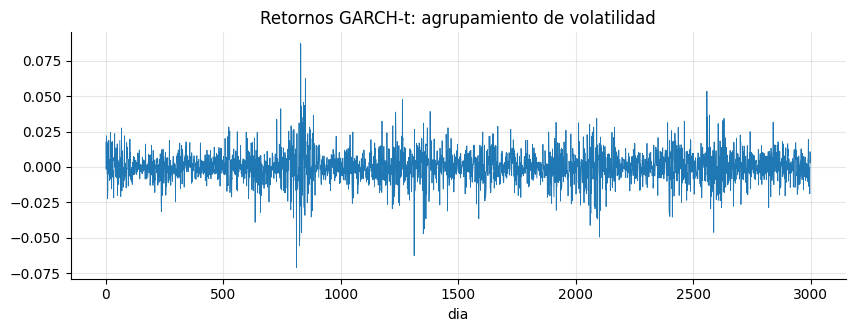

In [9]:
OMEGA, ALFA, BETA, NU_G = 2e-6, 0.08, 0.90, 6
Q = 0.99; P = 1 - Q

def simular_garch(T, seed, burn=500):
    rg = np.random.default_rng(seed); n = T + burn
    z = rg.standard_t(NU_G, n) * np.sqrt((NU_G - 2) / NU_G)
    r = np.zeros(n); h = np.zeros(n); h[0] = OMEGA / (1 - ALFA - BETA)
    for t in range(1, n):
        h[t] = OMEGA + ALFA * r[t - 1] ** 2 + BETA * h[t - 1]
        r[t] = np.sqrt(h[t]) * z[t]
    return r[burn:], np.sqrt(h[burn:])

r_ej, sig_ej = simular_garch(3000, 1)
print(f"vol incondicional teorica = {np.sqrt(OMEGA / (1 - ALFA - BETA)):.4f} | desvio muestral = {r_ej.std():.4f} | curtosis exceso = {stats.kurtosis(r_ej):.1f}")
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.plot(r_ej, lw=0.6); ax.set_title("Retornos GARCH-t: agrupamiento de volatilidad"); ax.set_xlabel("dia"); plt.show()

In [10]:
def ewma_vol(r, lam=0.94, arranque=250):
    s2 = np.empty(len(r)); s2[0] = r[:arranque].var()
    for t in range(1, len(r)): s2[t] = lam * s2[t - 1] + (1 - lam) * r[t - 1] ** 2
    return np.sqrt(s2)                                               # s2[t] solo usa informacion hasta t-1

def var_metodos(r):
    T = len(r); out = {}
    def rolling_q(x, w, q):
        v = sliding_window_view(x, w)[:-1]                           # ventana w que termina en t-1 para predecir t
        res = np.full(T, np.nan); res[w:] = np.quantile(v, q, axis=1); return res
    out["historico 250"] = -rolling_q(r, 250, 1 - Q)
    out["historico 500"] = -rolling_q(r, 500, 1 - Q)
    s250 = np.full(T, np.nan); s250[250:] = sliding_window_view(r, 250)[:-1].std(axis=1, ddof=1)
    out["normal 250"] = stats.norm.ppf(Q) * s250
    sig = ewma_vol(r)
    out["EWMA-normal"] = stats.norm.ppf(Q) * sig
    z = r / sig
    zq = np.full(T, np.nan); zq[500:] = np.quantile(sliding_window_view(z[:-1], 500), 1 - Q, axis=1)[:T - 500]
    out["FHS-EWMA"] = -zq * sig
    return out

def excepciones(r, var):
    ok = ~np.isnan(var); return (r[ok] < -var[ok]).astype(int), ok

V = var_metodos(r_ej)
filas = {}
for m, v in V.items():
    x, ok = excepciones(r_ej, v)
    pv = pvalores(x, P)
    filas[m] = {"dias": len(x), "excepciones": int(x.sum()), "tasa_%": x.mean() * 100, "p_Kupiec": pv["pof"], "p_independencia": pv["ind"], "p_cobertura_condicional": pv["cc"]}
una = pd.DataFrame(filas).T
una.round(4)

,dias,excepciones,tasa_%,p_Kupiec,p_independencia,p_cobertura_condicional
historico 250,"2,750.0000",49.0000,1.7818,0.0002,0.0675,0.0002
historico 500,"2,500.0000",41.0000,1.6400,0.0032,0.0321,0.0013
normal 250,"2,750.0000",61.0000,2.2182,0.0000,0.0572,0.0000
EWMA-normal,"3,000.0000",51.0000,1.7000,0.0005,0.2880,0.0012
FHS-EWMA,"2,500.0000",29.0000,1.1600,0.4330,0.4092,0.5231


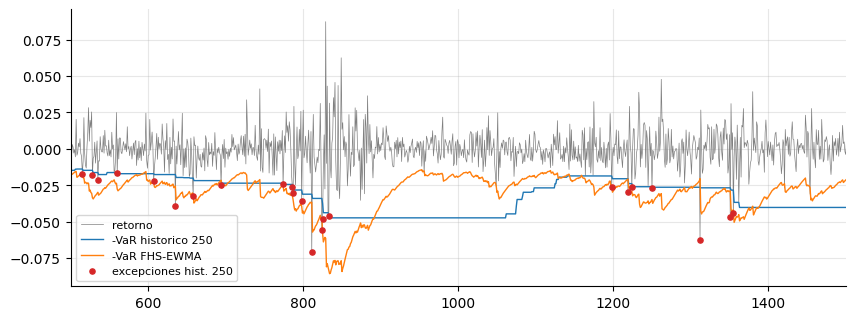

Lectura (una sola historia de 3000 dias):
  historico 250 : 49 excepciones (1.78% vs 1% esperado) | Kupiec p=0.000 | independencia p=0.067 | cc p=0.000
  historico 500 : 41 excepciones (1.64% vs 1% esperado) | Kupiec p=0.003 | independencia p=0.032 | cc p=0.001
  normal 250    : 61 excepciones (2.22% vs 1% esperado) | Kupiec p=0.000 | independencia p=0.057 | cc p=0.000
  EWMA-normal   : 51 excepciones (1.70% vs 1% esperado) | Kupiec p=0.000 | independencia p=0.288 | cc p=0.001
  FHS-EWMA      : 29 excepciones (1.16% vs 1% esperado) | Kupiec p=0.433 | independencia p=0.409 | cc p=0.523


In [11]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(r_ej, lw=0.5, color="gray", label="retorno")
for m in ("historico 250", "FHS-EWMA"):
    ax.plot(-V[m], lw=1, label=f"-VaR {m}")
ex = np.flatnonzero(r_ej < -V["historico 250"]); ax.scatter(ex, r_ej[ex], color="C3", s=14, zorder=5, label="excepciones hist. 250")
ax.set_xlim(500, 1500); ax.legend(loc="lower left", fontsize=8); plt.show()
print("Lectura (una sola historia de 3000 dias):")
for m in una.index:
    f = una.loc[m]
    print(f"  {m:14s}: {int(f['excepciones'])} excepciones ({f['tasa_%']:.2f}% vs 1% esperado) | Kupiec p={f['p_Kupiec']:.3f} | independencia p={f['p_independencia']:.3f} | cc p={f['p_cobertura_condicional']:.3f}")

Una sola historia puede engañar: con $R=1$ no se sabe si un resultado es la regla o la excepción. Se repite sobre **200 historias independientes** de 2.500 días y se mide, por método, la **tasa media de excepciones** y la **proporción de historias en que cada prueba rechaza**.

In [12]:
def experimento(R=200, T=2500, seed0=100):
    filas = []
    for i in range(R):
        r, _ = simular_garch(T, seed0 + i)
        for m, v in var_metodos(r).items():
            x, ok = excepciones(r, v); pv = pvalores(x, P)
            filas.append({"metodo": m, "tasa_%": x.mean() * 100, "rech_Kupiec": pv["pof"] < 0.05, "rech_independencia": pv["ind"] < 0.05, "rech_cc": pv["cc"] < 0.05})
    return pd.DataFrame(filas)

res = experimento()
resumen = res.groupby("metodo").agg(**{"tasa_media_%": ("tasa_%", "mean"), "tasa_P5": ("tasa_%", lambda s: s.quantile(.05)), "tasa_P95": ("tasa_%", lambda s: s.quantile(.95)),
                                       "rechaza_Kupiec": ("rech_Kupiec", "mean"), "rechaza_independencia": ("rech_independencia", "mean"), "rechaza_cc": ("rech_cc", "mean")})
resumen.round(3)

,tasa_media_%,tasa_P5,tasa_P95,rechaza_Kupiec,rechaza_independencia,rechaza_cc
metodo,,,,,,
EWMA-normal,1.7920,1.4800,2.1200,0.9700,0.0500,0.9450
FHS-EWMA,1.1880,0.9500,1.4000,0.0150,0.0200,0.0150
historico 250,1.5640,1.2440,1.9110,0.7350,0.2550,0.7250
historico 500,1.3280,0.9500,1.7520,0.2800,0.2350,0.3400
normal 250,1.9060,1.4200,2.4000,0.9300,0.3200,0.9200


In [13]:
print("Lectura (200 historias de 2500 dias, tasa esperada 1%):")
for m in resumen.index:
    f = resumen.loc[m]
    print(f"  {m:14s}: tasa media {f['tasa_media_%']:.2f}% | rechaza cobertura {f['rechaza_Kupiec']:.0%} | rechaza independencia {f['rechaza_independencia']:.0%} | rechaza cobertura condicional {f['rechaza_cc']:.0%}")
estatico = resumen.loc[["historico 250", "historico 500", "normal 250"], "rechaza_independencia"].mean()
dinamico = resumen.loc[["EWMA-normal", "FHS-EWMA"], "rechaza_independencia"].mean()
print(f"  Los metodos con volatilidad CONSTANTE dentro de la ventana rechazan independencia en promedio {estatico:.0%} de las historias; los que ADAPTAN la volatilidad, {dinamico:.0%}.")
e_, f_ = resumen.loc["EWMA-normal"], resumen.loc["FHS-EWMA"]
print(f"  Adaptar la volatilidad arregla la INDEPENDENCIA pero no la COBERTURA: EWMA-normal rechaza independencia {e_['rechaza_independencia']:.0%} pero cobertura {e_['rechaza_Kupiec']:.0%} (tasa {e_['tasa_media_%']:.2f}%): usa cuantiles normales sobre innovaciones t, y la cola es mas gruesa.")
print(f"  FHS-EWMA corrige ambas (cobertura {f_['rechaza_Kupiec']:.0%}, independencia {f_['rechaza_independencia']:.0%}, tasa {f_['tasa_media_%']:.2f}%) porque adapta la volatilidad Y usa el cuantil empirico de los residuos estandarizados.")

Lectura (200 historias de 2500 dias, tasa esperada 1%):
  EWMA-normal   : tasa media 1.79% | rechaza cobertura 97% | rechaza independencia 5% | rechaza cobertura condicional 94%
  FHS-EWMA      : tasa media 1.19% | rechaza cobertura 2% | rechaza independencia 2% | rechaza cobertura condicional 2%
  historico 250 : tasa media 1.56% | rechaza cobertura 74% | rechaza independencia 26% | rechaza cobertura condicional 72%
  historico 500 : tasa media 1.33% | rechaza cobertura 28% | rechaza independencia 24% | rechaza cobertura condicional 34%
  normal 250    : tasa media 1.91% | rechaza cobertura 93% | rechaza independencia 32% | rechaza cobertura condicional 92%
  Los metodos con volatilidad CONSTANTE dentro de la ventana rechazan independencia en promedio 27% de las historias; los que ADAPTAN la volatilidad, 4%.
  Adaptar la volatilidad arregla la INDEPENDENCIA pero no la COBERTURA: EWMA-normal rechaza independencia 5% pero cobertura 97% (tasa 1.79%): usa cuantiles normales sobre innovaci

## 6. El semáforo en el tiempo

Para cada día se cuentan las excepciones de los últimos 250 días y se clasifica en verde/amarillo/rojo. Con un modelo correcto e independiente, ≈ 89 % de los días deberían ser verdes (sección 2).

In [14]:
def zona_diaria(x):
    c = np.convolve(x, np.ones(250), mode="valid")
    return np.where(c <= 4, "verde", np.where(c <= 9, "amarillo", "rojo"))

filas = {}
for i in range(60):
    r, _ = simular_garch(2500, 900 + i)
    for m, v in var_metodos(r).items():
        x, ok = excepciones(r, v); z = zona_diaria(x)
        d = filas.setdefault(m, {"verde": [], "amarillo": [], "rojo": []})
        for k in d: d[k].append((z == k).mean())
zonas = pd.DataFrame({m: {k: np.mean(v) for k, v in d.items()} for m, d in filas.items()}).T
zonas.round(3)

,verde,amarillo,rojo
historico 250,0.6590,0.3150,0.0260
historico 500,0.7190,0.2380,0.0430
normal 250,0.5430,0.3810,0.0760
EWMA-normal,0.5150,0.4790,0.0060
FHS-EWMA,0.8560,0.1440,0.0000


In [15]:
print("Lectura: fraccion de dias en cada zona (con un modelo correcto e independiente: verde ~89%, amarillo+rojo ~11%):")
for m in zonas.index:
    print(f"  {m:14s}: verde {zonas.loc[m, 'verde']:.0%}, amarillo {zonas.loc[m, 'amarillo']:.0%}, rojo {zonas.loc[m, 'rojo']:.0%}")

Lectura: fraccion de dias en cada zona (con un modelo correcto e independiente: verde ~89%, amarillo+rojo ~11%):
  historico 250 : verde 66%, amarillo 31%, rojo 3%
  historico 500 : verde 72%, amarillo 24%, rojo 4%
  normal 250    : verde 54%, amarillo 38%, rojo 8%
  EWMA-normal   : verde 51%, amarillo 48%, rojo 1%
  FHS-EWMA      : verde 86%, amarillo 14%, rojo 0%


## 7. Pruebas automáticas

In [16]:
# 7.1 las pruebas se verificaron con un caso manual; ademas, estadisticos no negativos y p-valores en [0,1]
for n_ in (100, 500):
    xx = (np.random.default_rng(n_).random(n_) < 0.02).astype(int)
    assert lr_pof(xx, 0.01) >= -1e-9 and lr_ind(xx) >= -1e-9
    assert all(0 <= v <= 1 for v in pvalores(xx, 0.01).values())
# 7.2 sin ninguna excepcion o con todas, las funciones no devuelven NaN
for xx in (np.zeros(250, int), np.ones(250, int)):
    assert np.isfinite(lr_pof(xx, 0.01)) and np.isfinite(lr_ind(xx))
# 7.3 el semaforo de Basilea: probabilidades acumuladas bajo la nula
assert 0.89 < acum[0] < 0.895 and 0.9997 < acum[1] < 0.9998
# 7.4 calibracion: el Kupiec asintotico rechaza mas de 5% con n=250; con n grande se acerca a 5%; el exacto es conservador
assert tam.loc[250, "pof"] > 0.06 and abs(tam.loc[2500, "pof"] - 0.05) < 0.03
assert tam.loc[250, "exacto"] < 0.05
assert (tam["ind"] < 0.03).all() and (tam["cc"] < 0.04).all()         # las pruebas de Christoffersen son conservadoras con p=1%
# 7.4b descomposicion exacta: el exceso del Kupiec asintotico viene del lado de pocas excepciones (k=0) y no del de muchas
assert desc.loc["asintotica", "rechaza_con_pocas_excepciones(k<2.5)"] > 0.05 and desc.loc["exacta", "rechaza_con_pocas_excepciones(k<2.5)"] < 0.01
assert desc.loc["asintotica", "rechaza_con_muchas(k>2.5)"] < desc.loc["exacta", "rechaza_con_muchas(k>2.5)"] + 1e-12
assert abs(desc.loc["asintotica", "total"] - tam.loc[250, "pof"]) < 0.02, "la descomposicion exacta debe coincidir con la simulacion"
assert pot.loc[("tasa 2.0%", 250), "Kupiec asintotico"] < pot.loc[("tasa 2.0%", 250), "Kupiec exacto"]
# 7.5 potencia: crece con n; con n=250 es baja para una tasa del doble (excepciones 2% en lugar de 1%)
for esc in ("tasa 1.5%", "tasa 2.0%", "tasa 3.0%"):
    assert pot.loc[(esc, 2500), "Kupiec exacto"] > pot.loc[(esc, 250), "Kupiec exacto"]
assert pot.loc[("tasa 2.0%", 250), "Kupiec exacto"] < 0.8
assert pot.loc[("tasa 3.0%", 250), "Kupiec exacto"] > pot.loc[("tasa 1.5%", 250), "Kupiec exacto"]
assert pot.loc[("agrupado (tasa 1%)", 2500), "independencia"] > pot.loc[("agrupado (tasa 1%)", 250), "independencia"]
# 7.6 en el mundo GARCH-t, los metodos de volatilidad constante rechazan mas la independencia que los que adaptan la volatilidad
assert estatico > dinamico + 0.2, f"estaticos {estatico:.2f} vs dinamicos {dinamico:.2f}"
# 7.7 la tasa de excepciones de los metodos que adaptan la volatilidad esta mas cerca del 1% nominal
assert abs(resumen.loc["FHS-EWMA", "tasa_media_%"] - 1) < abs(resumen.loc["normal 250", "tasa_media_%"] - 1) + 0.5
# 7.8 el semaforo: con un modelo correcto el verde es ~89%; los estaticos pasan menos tiempo en verde que el FHS
assert zonas.loc["FHS-EWMA", "verde"] > zonas.loc["historico 250", "verde"] - 0.05
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Calibración | El exceso de rechazo del Kupiec asintótico (≈10 %) viene entero del lado de cero excepciones; del lado de riesgo necesita una excepción más que el exacto. Las pruebas de independencia rechazan solo 1–3 % | Preferir la prueba exacta con ventanas cortas y mirar de qué lado rechaza |
| Potencia | Con 250 días el backtest detecta pocas veces un VaR que deja pasar el doble de excepciones | Aprobar un backtest corto no demuestra que el modelo sea correcto |
| Independencia | Las excepciones agrupadas con la tasa correcta pasan Kupiec y solo las detecta la prueba de independencia, con más datos | Probar siempre cobertura Y independencia |
| Mundo GARCH-t | Adaptar la volatilidad arregla la independencia (EWMA-normal la pasa) pero no la cobertura si la cola es normal; FHS-EWMA pasa ambas | Adaptar la volatilidad Y modelar la cola de los residuos |
| Semáforo | Un modelo correcto cae fuera de verde ≈ 11 % de los días solo por azar | No leer un amarillo aislado como evidencia de falla |

**Límites que no deben ocultarse**

- Las excepciones se simulan con un proceso GARCH-t cuyos parámetros son una elección del autor; con datos reales hay saltos, cambios de régimen y colas distintas.
- Se evalúa solo el VaR a un día al 99 %; otros niveles y horizontes cambian la potencia y la calibración.
- Los métodos adaptativos usan λ=0,94 y ventanas fijas; no se afinaron.
- La potencia se midió para dos tipos de modelo defectuoso (tasa equivocada y agrupamiento); hay otros (p. ej., sesgo por tamaño del retorno).
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.